# Arbitrary mask layouts: polygons at any angle

Real layouts are not only lines, spaces and rectangles. Wires run at 45°,
contacts and vias are drawn as octagons or come out of the mask writer
round, DRAM cells sit on hexagonal lattices, and inverse lithography (ILT)
produces curvilinear masks that the mask shops can now write with
multi-beam writers. This notebook simulates such layouts with
`pyoptics.litho`:

1. **Exact polygon transforms**: the Fourier coefficients of any polygon
   are a sum over its edges (Lee and Mittra), so the mask is never
   pixelated (`pyoptics.polygons`, shared with the segmented telescope
   pupils of notebook 98 (segmented mirrors) and the iris of notebook 91, sunstars). How large the error
   of a pixelated mask is.
2. **Layouts from layout files**: `MaskLayout.from_polygons()` and
   `MaskLayout.from_gds()` take polygons in the form that gdstk and gdspy
   return (pyoptics reads no GDSII or OASIS itself): layers, a window that
   becomes the simulation period, units.
3. **45° lines**: which illumination prints which orientation (C-quad
   against Quasar), and why two orientations need a compromise.
4. **A 45° jog in a dense bus**: the pitch shrinks by $\sqrt 2$ in the
   diagonal, a classic hotspot.
5. **A hexagonal contact array** (the DRAM storage node pattern): square
   against round mask holes, annular against hexapole illumination.
6. **Curvilinear masks**: how many vertices a round shape needs.

Setup as in notebooks 32 (lithography toolbox) and 40 (OPC): ArF water immersion, NA 1.35, 6 %
attenuated PSM as a thin mask, threshold 0.3 of the open frame, lengths in
nm at wafer scale.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from scipy.interpolate import RegularGridInterpolator

from pyoptics import polygons as pg
from pyoptics.litho import Illumination, LithoSimulation, MaskLayout, Projector, ThinMask, plot
from pyoptics.litho.mask import gds_polygons

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

projector = Projector(1.35, 193.0, n=1.437)
stack = ThinMask.att_psm()
THRESHOLD = 0.3


def draw(ax, polygons, **kwargs):
    kwargs.setdefault("fill", False)
    for P in polygons:
        ax.add_patch(Polygon(P, closed=True, **kwargs))


def diagonal_lines(pitch, cd, tone="clear"):
    # lines along (1, 1) with the perpendicular pitch `pitch`: one line per
    # square cell of side pitch*sqrt(2), drawn as a parallelogram that
    # sticks out of the cell (the periodic copies continue it)
    a, d = pitch*np.sqrt(2), cd*np.sqrt(2)/2
    return MaskLayout.from_polygons(a, a, [[(-a/2 - d, -a/2), (-a/2 + d, -a/2), (a/2 + d, a/2), (a/2 - d, a/2)]],
                                    tone, "45° L/S {:g}/{:g}".format(cd, pitch))


def straight_lines(pitch, cd, tone="clear"):
    # the same lines along y, as a polygon layout (periodic in x and y)
    return MaskLayout.from_polygons(pitch, pitch, [[(-cd/2, -pitch/2), (cd/2, -pitch/2), (cd/2, pitch/2),
                                                    (-cd/2, pitch/2)]], tone, "L/S {:g}/{:g}".format(cd, pitch))

## 1. Exact Fourier transforms of polygons

A thin mask is a transmission $t(x, y)$ that takes two values, clear and
absorber. On a periodic mask the imaging needs its Fourier coefficients
$c_{mn}$ at the orders $(m/p_x, n/p_y)$ that pass the pupil. For a polygon
$P$ the area integral

$$F_P(\mathbf k) = \int_P e^{-i\mathbf k\cdot\mathbf r}\,dA
= \frac{i}{k^2}\sum_j (\mathbf k\cdot\mathbf N_j)\,e^{-i\mathbf k\cdot\mathbf m_j}\,
\mathrm{sinc}\,\frac{\mathbf k\cdot\mathbf e_j}{2}$$

is a sum over the edges (vector $\mathbf e_j$, midpoint $\mathbf m_j$,
outward normal times length $\mathbf N_j$), by Gauss' theorem with
$e^{-i\mathbf k\cdot\mathbf r} = \nabla\cdot(i\mathbf k e^{-i\mathbf k\cdot\mathbf r}/k^2)$.
The coefficients of the periodic mask are
$c_{mn} = \sum_P F_P(2\pi m/p_x, 2\pi n/p_y)/(p_x p_y)$, *whether or not the
polygons lie inside one period*: the transform of one copy sampled at the
reciprocal lattice is the Fourier series of the periodized pattern. That
is why the 45° lines above can be drawn as one long parallelogram per
cell.

Manhattan polygons are still cut into rectangles (products of sinc
functions, as before); everything else uses `pyoptics.polygons.polygon_ft()`.
The alternative, common in simple simulators, is to sample the mask on a
grid and take an FFT. For 45° lines at 100 nm pitch, the error of the
first orders against the pixel size:

exact |c| of the orders (m, n) = (-1..1, -1..1):
[[0.     0.     0.3183]
 [0.     0.5    0.    ]
 [0.3183 0.     0.    ]]
pixel 20.0 nm: error 7.1e-02 (binary), 2.7e-02 (antialiased)
pixel 10.0 nm: error 2.7e-03 (binary), 9.3e-03 (antialiased)
pixel  5.0 nm: error 1.5e-02 (binary), 4.6e-03 (antialiased)
pixel  2.0 nm: error 7.0e-03 (binary), 1.7e-03 (antialiased)
pixel  1.0 nm: error 3.5e-03 (binary), 7.9e-04 (antialiased)
pixel  0.5 nm: error 1.8e-03 (binary), 4.4e-04 (antialiased)


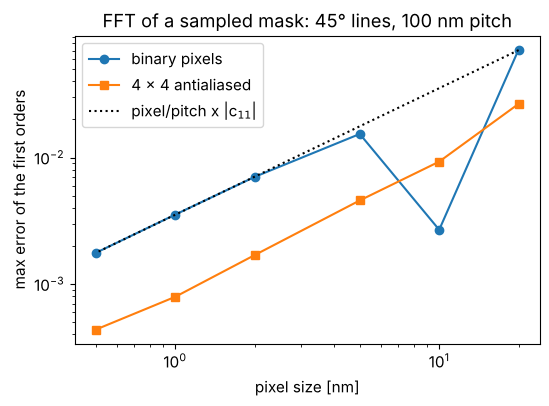

In [2]:
L45 = diagonal_lines(100, 50)
p = L45.pitch_x
m = np.array([-1, 0, 1])
exact = L45.region_coefficients(m, m)["feature"]
print("exact |c| of the orders (m, n) = (-1..1, -1..1):")
print(np.round(np.abs(exact), 4))


def fft_coefficients(layout, N, antialias=1):
    # sample (pixel centers; antialias > 1: average over sub-pixels) and FFT
    h = layout.pitch_x/N
    s = (np.arange(antialias) + 0.5)/antialias - 0.5
    x = -layout.pitch_x/2 + (np.arange(N) + 0.5)*h
    t = np.mean([layout.inside(x[None, :] + a*h, x[:, None] + b*h) for a in s for b in s], axis=0)
    C = np.fft.fft2(t)/t.size
    k = np.fft.fftfreq(N, 1/N)
    phase = np.exp(-2j*np.pi*(k[None, :] + k[:, None])*x[0]/layout.pitch_x)   # grid starts at x[0]
    C = C*phase
    return C[np.ix_(m % N, m % N)]


pixels = np.array([20, 10, 5, 2, 1, 0.5])
err = {aa: [np.max(np.abs(fft_coefficients(L45, int(round(p/h)), aa) - exact)) for h in pixels] for aa in (1, 4)}
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(pixels, err[1], "o-", label="binary pixels")
ax.loglog(pixels, err[4], "s-", label="4 x 4 antialiased")
ax.loglog(pixels, np.abs(exact[1, 1])*pixels/p, "k:", label="pixel/pitch x |c$_{11}$|")
ax.set_xlabel("pixel size [nm]"), ax.set_ylabel("max error of the first orders")
ax.set_title("FFT of a sampled mask: 45° lines, 100 nm pitch"), ax.legend()
for h, e1, e4 in zip(pixels, err[1], err[4]):
    print("pixel {:4.1f} nm: error {:.1e} (binary), {:.1e} (antialiased)".format(h, e1, e4))

The staircase of a binary pixelated 45° edge shifts the edge by up to half
a pixel. The error of the orders falls only linearly with the pixel size,
and irregularly at coarse pixels, depending on where the edges cross the
grid (the lucky 10 nm point). Antialiasing gains a factor of about four,
but errors around $10^{-3}$ still need pixels of about 1 nm, and such
errors matter for CD at the 0.1 nm level (the MEEF multiplies them). With the edge sum there is no grid: the cost
is one complex exponential per edge and order, and the result is exact to
rounding. For Manhattan layouts both methods in `MaskLayout` agree to
$10^{-16}$ (see the tests); a rectangle cut into two triangles gives the
same image as the rectangle.

## 2. Layouts from layout files

pyoptics does not read GDSII or OASIS files and does not depend on a
layout library. It takes polygons as $(N, 2)$ arrays, and
`MaskLayout.from_gds()` understands what the usual Python layout libraries
return, by duck typing (`litho.mask.gds_polygons()`):

- **gdstk**: a `Cell` (its `get_polygons()`, references and repetitions
  flattened), `Polygon` objects (`points`, `layer`, `datatype`), paths
  (`FlexPath`, `RobustPath`, through `to_polygons()`),
- **gdspy**: a `Cell` or `CellReference` (`get_polygons(by_spec=True)`),
  `PolygonSet`s (`polygons`, `layers`, `datatypes`),
- a dict `{(layer, datatype): [polygons]}`, which is what gdspy's
  `get_polygons(by_spec=True)` returns and is easy to build from any other
  reader, or plain lists of polygons.

With gdstk installed, reading a file is

```python
import gdstk
lib = gdstk.read_gds("chip.gds")          # or gdstk.read_oas(...)
top = lib.top_level()[0]
layout = MaskLayout.from_gds(top, window=(x0, y0, x1, y1), layer=17, datatype=0,
                             tone="dark", scale=1e3)   # layout in um, simulation in nm
```

The **window** is one period of the simulated mask: the polygons are
clipped to it (Sutherland-Hodgman, `polygons.clip_to_rectangle()`), and its
center becomes the origin. For a cell of a periodic array (an SRAM or DRAM
array, a contact array) the window is the unit cell and the simulation is
exact. For a clip from a random layout the periodic copies are one window
away: choose the window a few $\lambda/\mathrm{NA}$ (here 143 nm) larger
than the region of interest. **Tone**: the drawn polygons are absorber on a
clear field (`tone="clear"`, e.g. a gate layer in positive resist) or
openings in a dark field (`tone="dark"`, contacts, vias and the trenches of
a damascene metal layer). Layout coordinates are taken at wafer scale (1x),
as drawn; the reduction of the projector only enters the angles at the
mask.

Two conditions on the polygons. They must not **overlap** (each other or
their own periodic copies), or the overlap counts twice: layout files
often hold overlapping shapes, so merge each layer first, e.g.
`gdstk.boolean(polygons, [], "or")`; `from_polygons()` checks on a grid and
raises. (Manhattan polygons are merged exactly by the rectangle
decomposition.) Polygons with **holes** come as keyhole polygons, as in
GDSII: the two edges of the cut cancel in the edge sum.

A small library as a dict, as gdspy would return it: a metal layer (1/0)
with a bus of nine wires with two 45° jogs, a via layer (2/0) with
octagons, and a marker layer (63/0) that should not be simulated. The
wires are drawn as paths of constant width (`polygons.path_polygon()`,
miter joins as in a GDSII path).

{(1, 0): 9, (2, 0): 3, (63, 0): 1}
layer 1: 9 polygons, layers 1 and 2: 12


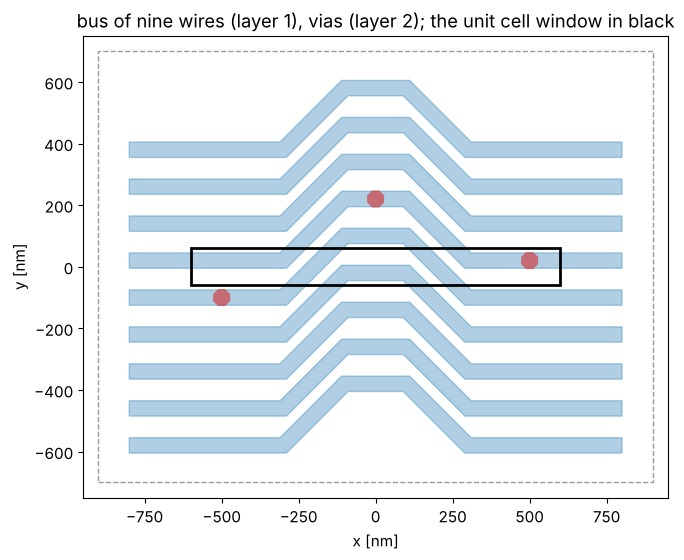

In [3]:
W = 50.0                                                         # wire width


def bus(spacing, n=9):
    centre = np.array([(-800, -100), (-300, -100), (-100, 100), (100, 100), (300, -100), (800, -100)], float)
    return [pg.path_polygon(centre + [0, (i - (n - 1)/2)*spacing], W) for i in range(n)]


library = {(1, 0): bus(120.0),
           (2, 0): [pg.regular_polygon(8, 30, (x, y), np.pi/8) for x, y in [(-500, -100), (500, 20), (0, 220)]],
           (63, 0): [np.array([(-900, -700), (900, -700), (900, 700), (-900, 700)])]}
print({spec: len(polys) for spec, polys in library.items()})
print("layer 1:", len(gds_polygons(library, layer=1)), "polygons,",
      "layers 1 and 2:", len(gds_polygons(library, layer=[1, 2])))

fig, ax = plt.subplots(figsize=(10, 6))
draw(ax, library[(1, 0)], fc="C0", alpha=0.35, fill=True, ec="C0")
draw(ax, library[(2, 0)], fc="C3", alpha=0.6, fill=True)
draw(ax, library[(63, 0)], ec="0.6", ls="--")
ax.add_patch(plt.Rectangle((-600, -60), 1200, 120, fill=False, ec="k", lw=2))
ax.set_xlim(-950, 950), ax.set_ylim(-750, 750), ax.set_aspect("equal")
ax.set_xlabel("x [nm]"), ax.set_ylabel("y [nm]")
ax.set_title("bus of nine wires (layer 1), vias (layer 2); the unit cell window in black");

Away from its ends the bus is periodic in $y$ with the wire pitch, and the
wire returns to its height after the two jogs, so the bus is periodic in
$x$ with 1200 nm as well. One cell, $1200 \times 120$ nm, holds pieces of
three wires after clipping; repeated, they make the infinite bus:

MaskLayout(bus, 120 nm pitch, pitch=(1200.0, 120.0), tone=dark) - 3 clipped polygons, Manhattan: False


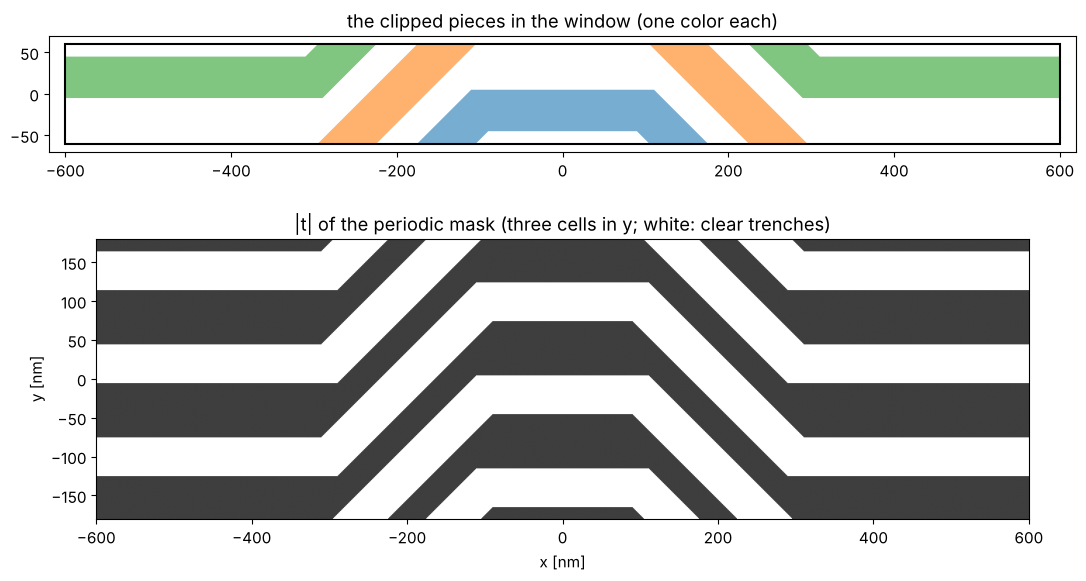

In [4]:
cell = MaskLayout.from_gds(library, (-600, -60, 600, 60), layer=1, tone="dark", name="bus, 120 nm pitch")
print(cell, "-", len(cell.polygons), "clipped polygons, Manhattan:", cell.manhattan)
fig, axs = plt.subplots(2, 1, figsize=(11, 6.5))
for k, P in enumerate(cell.polygons):
    axs[0].add_patch(Polygon(P, closed=True, alpha=0.6, fc="C{}".format(k)))
axs[0].add_patch(plt.Rectangle((-600, -60), 1200, 120, fill=False, ec="k", lw=1.5))
axs[0].set_xlim(-620, 620), axs[0].set_ylim(-70, 70), axs[0].set_aspect("equal")
axs[0].set_title("the clipped pieces in the window (one color each)")
xs, ys = np.linspace(-600, 600, 1201), np.linspace(-180, 180, 361)
axs[1].imshow(np.abs(cell.transmission(xs, ys, t_absorber=stack.t_absorber)), origin="lower", cmap="gray",
              extent=(xs[0], xs[-1], ys[0], ys[-1]), vmin=0, vmax=1)
axs[1].set_xlabel("x [nm]"), axs[1].set_ylabel("y [nm]")
axs[1].set_title("|t| of the periodic mask (three cells in y; white: clear trenches)")
plt.tight_layout()

## 3. Lines at 45°: which source prints which orientation

Dense lines diffract into orders perpendicular to the lines. Off-axis
illumination puts the source poles where the zeroth and a first order fit
into the pupil symmetrically. A **C-quad** (poles on the $x$ and $y$
axes) serves lines along $x$ and $y$, a **Quasar** (poles at 45°) serves
45° lines; both are standard settings. Lines at 50 % duty cycle through
pitch, TE (azimuthal) polarization, NILS at the nominal edges (for the
45° lines the cut along $x$ is $\sqrt 2$ longer and the slope $\sqrt 2$
smaller, so the NILS is the same as perpendicular to the lines):

84 simulations in 0.2 s


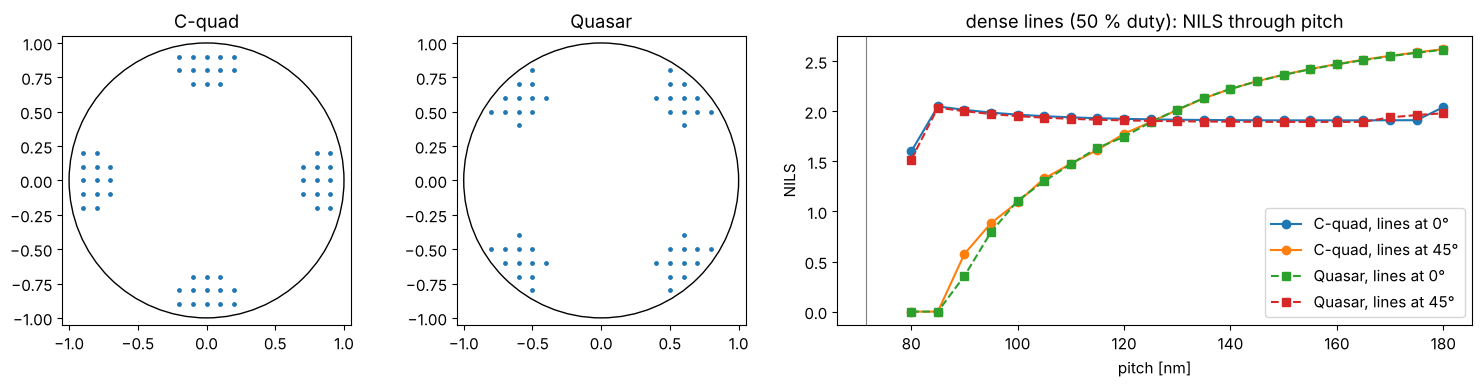

In [5]:
c_quad = Illumination.multipole((0, 90, 180, 270), 0.95, 0.7, 30, n_samples=21, polarization="TE", name="C-quad")
quasar = Illumination.multipole((45, 135, 225, 315), 0.95, 0.7, 30, n_samples=21, polarization="TE", name="Quasar")
pitches = np.arange(80, 181, 5)
nils = {}
t0 = time.time()
for ill in (c_quad, quasar):
    for name, make in (("0°", straight_lines), ("45°", diagonal_lines)):
        nils[ill.name, name] = [LithoSimulation(make(p, p/2), stack, ill, projector).nils() for p in pitches]
print("{} simulations in {:.1f} s".format(4*len(pitches), time.time() - t0))

fig, axs = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 1, 2]})
for ax, ill in zip(axs, (c_quad, quasar)):
    ax.scatter(ill.s_x, ill.s_y, s=6)
    ax.add_patch(plt.Circle((0, 0), 1, fill=False))
    ax.set_aspect("equal"), ax.set_xlim(-1.05, 1.05), ax.set_ylim(-1.05, 1.05), ax.set_title(ill.name)
for (ill, name), v in nils.items():
    axs[2].plot(pitches, v, "o-" if ill == "C-quad" else "s--", label="{}, lines at {}".format(ill, name))
axs[2].axvline(193/(2*1.35), color="gray", lw=0.8)
axs[2].set_xlabel("pitch [nm]"), axs[2].set_ylabel("NILS"), axs[2].legend()
axs[2].set_title("dense lines (50 % duty): NILS through pitch")
plt.tight_layout()

The two pairs of curves are the same up to the sampling of the source:
the system is symmetric under a rotation by 45° if source and mask rotate
together (the azimuthal polarization rotates with them), which is also a
check of the polygon transforms. At large pitches all four combinations
image well (the gray line is the resolution limit $\lambda/(2\mathrm{NA})$).
Below about 125 nm the mismatched pairs degrade and below 90 nm they print
nothing: for lines along $y$ under the Quasar, a source point at
$(\sigma_x, \sigma_y) = (0.58, 0.58)$ sends its first order to
$\sigma_x = 0.58 - \lambda/(p\,\mathrm{NA})$ at the same $\sigma_y$, which
leaves the pupil once $\lambda/(p\,\mathrm{NA}) > 1.4$, i.e. below 100 nm
pitch; at 85 nm no pole point gets a first order through. A layout with dense
lines in both orientations needs a compromise (an annular source, or a
source optimized for the mix, notebook 39, source optimization), which costs process window on
both; this is one reason why critical layers are drawn unidirectional and
why 45° wiring disappeared from advanced logic. Mixed orientations remain
at relaxed pitches, in analog and power devices, in photonics, and in
DRAM periphery.

## 4. A 45° jog in a dense bus

Back to the bus of section 2. The wires are 50 nm trenches at 120 nm
pitch. In the diagonal part the vertical spacing is still 120 nm, but the
perpendicular pitch is $120/\sqrt 2 = 85$ nm, and the wires keep their
drawn width of 50 nm: the space between them shrinks from 70 to 35 nm.
The bus is simulated as the exact periodic array (the unit cell window);
the dose prints the straight parts on size, from a 1D line/space pattern
of the same pitch:

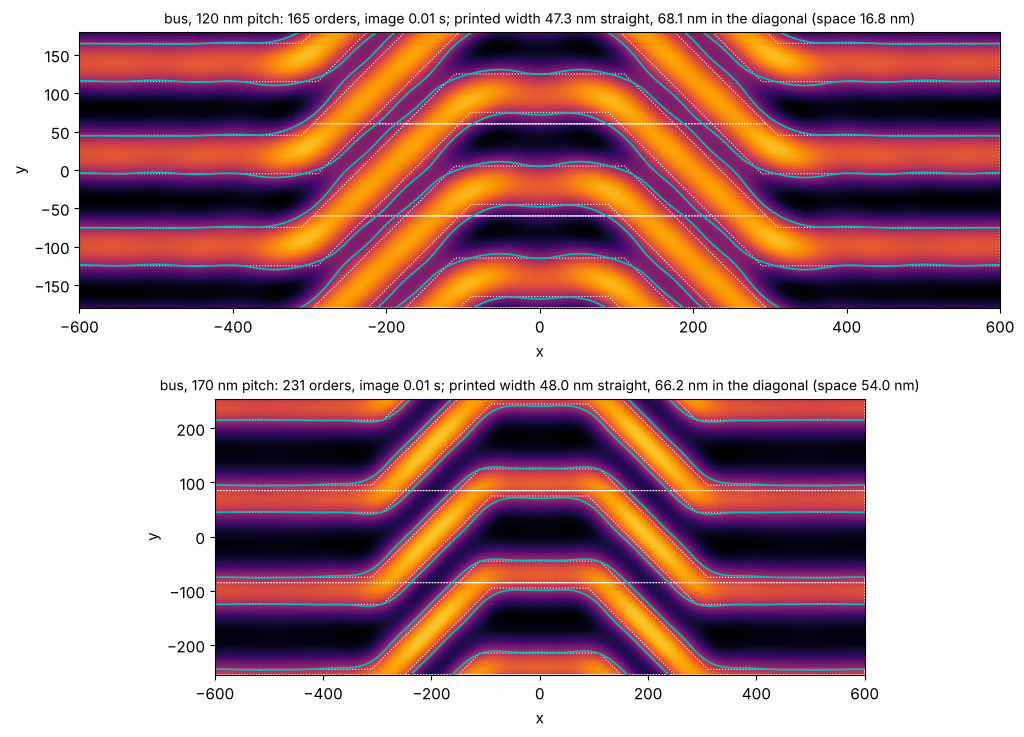

In [6]:
annular = Illumination.annular(0.9, 0.6, n_samples=21, polarization="TE")


def bus_cell(spacing):
    lib = {(1, 0): bus(spacing)}
    return MaskLayout.from_gds(lib, (-600, -spacing/2, 600, spacing/2), layer=1, tone="dark",
                               name="bus, {:g} nm pitch".format(spacing))


def perpendicular_cd(I, x, y, centre, direction, threshold, length=200, n=801):
    # printed width of the trench through `centre` along `direction` (unit
    # vector), from the image interpolated on the line
    f = RegularGridInterpolator((y, x), I)
    s = np.linspace(-length/2, length/2, n)
    pts = np.column_stack([centre[1] + s*direction[1], centre[0] + s*direction[0]])
    v = f(pts) - threshold
    i0 = n//2
    lo = next(i for i in range(i0, 0, -1) if v[i - 1] < 0)
    hi = next(i for i in range(i0, n - 1) if v[i + 1] < 0)
    s_lo = s[lo - 1] + (s[lo] - s[lo - 1])*(-v[lo - 1])/(v[lo] - v[lo - 1])
    s_hi = s[hi] + (s[hi + 1] - s[hi])*v[hi]/(v[hi] - v[hi + 1])
    return s_hi - s_lo


x = np.linspace(-600, 600, 481)
results = {}
fig, axs = plt.subplots(2, 1, figsize=(12, 7.5))
for ax, spacing in zip(axs, (120.0, 170.0)):
    L = bus_cell(spacing)
    dose = LithoSimulation(MaskLayout.lines_spaces(spacing, W, tone="dark"), stack, annular, projector) \
        .dose_to_size(W, THRESHOLD)
    sim = LithoSimulation(L, stack, annular, projector)
    y = np.linspace(-1.5*spacing, 1.5*spacing, int(3*spacing/2.5) + 1)
    t0 = time.time()
    I = sim.image(x, y)
    dt = time.time() - t0
    straight = perpendicular_cd(dose*I, x, y, (-500, -100 + spacing), (0, 1), THRESHOLD, spacing)
    diagonal = perpendicular_cd(dose*I, x, y, (-200, 0), (np.sqrt(0.5), -np.sqrt(0.5)), THRESHOLD,
                                spacing/np.sqrt(2))
    results[spacing] = (straight, diagonal)
    plot.plot_image(sim, x, dose*I, y, ax=ax, threshold=THRESHOLD, colorbar=False, vmax=0.6)
    ax.set_aspect("equal")
    ax.set_title("{}: {} orders, image {:.2f} s; printed width {:.1f} nm straight, {:.1f} nm in the diagonal "
                 "(space {:.1f} nm)".format(L.name, np.prod([2*k + 1 for k in L.max_orders(1.35, 193, 0.9)]), dt,
                                            straight, diagonal, spacing/np.sqrt(2) - diagonal), fontsize=10)
plt.tight_layout()

At 120 nm pitch the trenches in the diagonal print almost 70 nm wide
instead of 50 nm, and the space between them closes to about 17 nm (drawn:
35 nm): a bridging hotspot. The denser diagonal transmits more light than
the straight parts at the same dose, and its 85 nm pitch images with less
contrast under this source. Spreading the bus to 170 nm vertical spacing
gives the diagonal a 120 nm pitch: its trenches still print about 16 nm
wider than the straight parts (OPC would bias them), but the space stays
above 50 nm. The price is 40 % more area, which is why dense buses that
need 45° bends get their own rules. The image of the bus cell takes a
fraction of a second: the 120 nm cell has 33 x 5 orders.

(The dotted outlines in the image are those of the clipped polygons, so
the window borders show up as lines through the trenches; on the mask
they are not edges.)

## 5. A hexagonal contact array

DRAM storage node contacts sit on a hexagonal lattice: of all lattices it
packs the most holes at a given distance $p$ to the nearest neighbours,
and its six first orders lie on a circle, so a source with six poles
(hexapole) can use all of them. The lattice is periodic on a rectangular
cell $p \times \sqrt 3 p$ with two holes. Here $p = 120$ nm and holes of
the area of a 60 nm square, drawn as squares, as circles (64-gons) and as
hexagons:

In [7]:
p_hex, cd_hole = 120.0, 60.0
cell_x, cell_y = p_hex, np.sqrt(3)*p_hex
centres = [(-p_hex/4, -cell_y/4), (p_hex/4, cell_y/4)]
shapes = {
    "square": lambda c: pg.regular_polygon(4, cd_hole/np.sqrt(2), c, np.pi/4),
    "circle": lambda c: pg.circle_polygon(cd_hole/np.sqrt(np.pi), c, n=64),
    "hexagon": lambda c: pg.regular_polygon(6, np.sqrt(cd_hole**2/(1.5*np.sqrt(3))), c, np.pi/6),
}
hex_layouts = {name: MaskLayout.from_polygons(cell_x, cell_y, [f(c) for c in centres], tone="dark", name=name)
               for name, f in shapes.items()}
m, n = np.array([-1, 0, 1]), np.array([-2, -1, 0, 1, 2])
for name, L in hex_layouts.items():
    c = np.abs(L.region_coefficients(m, n)["feature"])
    print("{:8s} |c| order 0: {:.4f}, the six first orders: {}".format(
        name, c[2, 1], np.round([c[0, 1], c[4, 1], c[1, 0], c[1, 2], c[3, 0], c[3, 2]], 4)))

square   |c| order 0: 0.2887, the six first orders: [0.1545 0.1545 0.1596 0.1596 0.1596 0.1596]
circle   |c| order 0: 0.2887, the six first orders: [0.1617 0.1617 0.1617 0.1617 0.1617 0.1617]
hexagon  |c| order 0: 0.2887, the six first orders: [0.161 0.161 0.161 0.161 0.161 0.161]


The six first orders are $(m, n) = (0, \pm 2)$ and $(\pm 1, \pm 1)$ of the
rectangular cell. The circle and the hexagon give six equal amplitudes;
the square, which does not have the symmetry of the lattice, does not
(about 3 % difference). All other orders lie outside the pupil for any
source point (their spatial frequency $\geq 2/p$ against the cutoff
$2\,\mathrm{NA}/\lambda$), so the image depends on the hole shape only
through these seven numbers. Two sources, annular and a hexapole with
poles at 0°, 60°, ...:

circle, hexapole rotated by 30° (poles at 30°, 90°, ...): dose 5.21, NILS 1.12


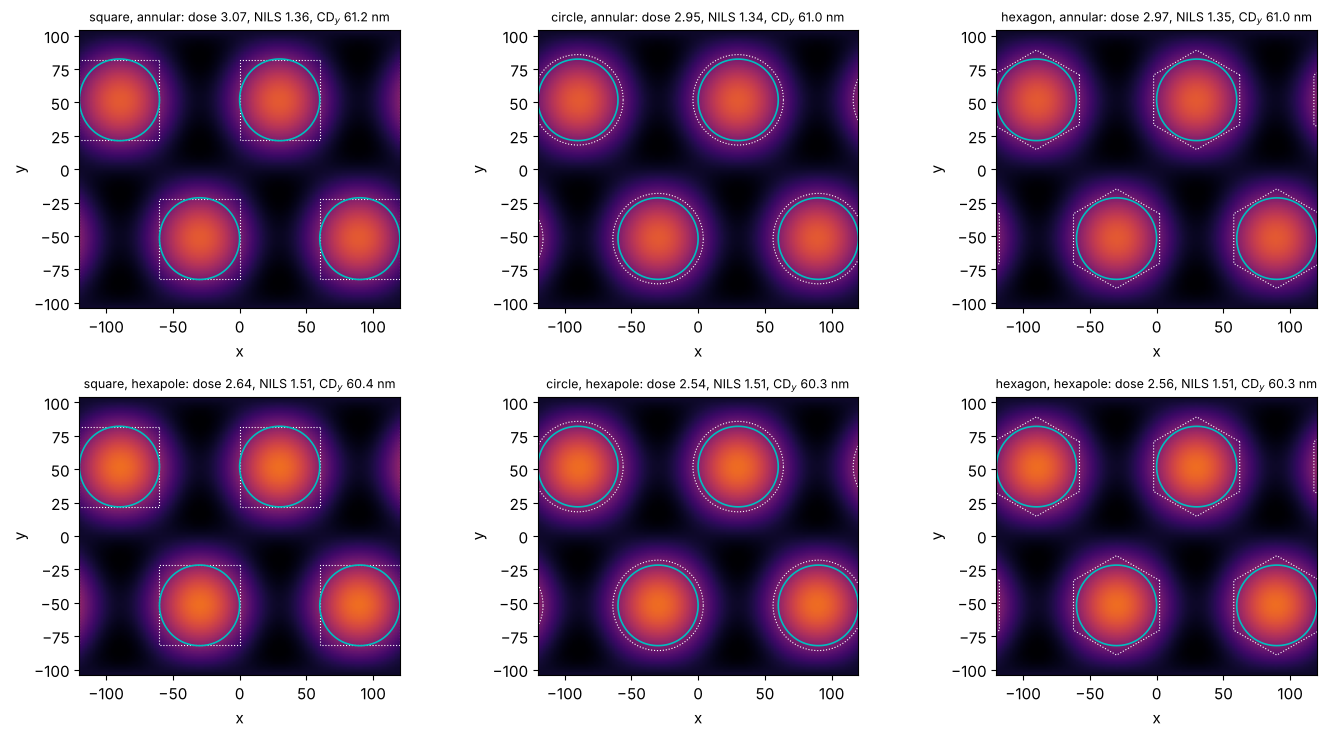

In [8]:
hex_sources = {
    "annular": Illumination.annular(0.9, 0.6, n_samples=21),
    "hexapole": Illumination.multipole(np.arange(0, 360, 60), 0.95, 0.65, 30, n_samples=21, name="hexapole"),
}
x = np.linspace(-cell_x, cell_x, 121)
y = np.linspace(-cell_y/2, cell_y/2, 105)
fig, axs = plt.subplots(2, 3, figsize=(14, 7.5))
for row, (sname, ill) in zip(axs, hex_sources.items()):
    for ax, (name, L) in zip(row, hex_layouts.items()):
        sim = LithoSimulation(L, stack, ill, projector)
        dose = sim.dose_to_size(cd_hole, THRESHOLD)
        I = dose*sim.image(x, y)
        plot.plot_image(sim, x, I, y, ax=ax, threshold=THRESHOLD, colorbar=False, vmax=0.6)
        ax.set_aspect("equal")
        ax.set_title("{}, {}: dose {:.2f}, NILS {:.2f}, CD$_y$ {:.1f} nm".format(
            name, sname, dose, sim.nils(THRESHOLD, dose), sim.cd(THRESHOLD, dose, direction="y")), fontsize=9)
plt.tight_layout()

rotated = Illumination.multipole(np.arange(30, 360, 60), 0.95, 0.65, 30, n_samples=21)
sim = LithoSimulation(hex_layouts["circle"], stack, rotated, projector)
dose = sim.dose_to_size(cd_hole, THRESHOLD)
print("circle, hexapole rotated by 30° (poles at 30°, 90°, ...): dose {:.2f}, NILS {:.2f}".format(
    dose, sim.nils(THRESHOLD, dose)))

The printed holes are nearly the same for all three mask shapes (the dose
is adjusted to a 60 nm CD along $x$); the round and hexagonal holes need
about 4 % less dose than the square, because they put a little more light
into the six first orders. The hexapole gains about 10 % NILS over the
annular source: from each pole, the zeroth order and two first orders pass
the pupil (three-beam interference), while the annular ring wastes the
source points between them. Rotating the hexapole by 30° (poles on the
first orders) leaves only two-beam interference from each pole and loses
NILS. That the mask shape barely matters for dense arrays is the reason
why simple mask shapes suffice there; it does matter for the MEEF and for
the edges of the array, where higher orders reach the pupil.

## 6. Curvilinear masks: how many vertices?

ILT gives smooth mask shapes. A layout format stores them as polygons
(OASIS, or GDSII with many vertices), and the mask writer approximates
them again. With the exact polygon transform the only question is how
finely the polygon must sample the curve: a circular 70 nm contact
(isolated, dark field) as an $n$-gon of the same area:

In [9]:
conventional = Illumination.conventional(0.5, n_samples=15)
u = np.linspace(-120, 120, 121)
ref = None
rows = []
for n_vert in (256, 4, 6, 8, 12, 16, 32, 64):
    L = MaskLayout.from_polygons(600, 600, [pg.circle_polygon(35, n=n_vert)], tone="dark")
    sim = LithoSimulation(L, stack, conventional, projector)
    I = sim.image(u, u)
    if ref is None:
        ref = I
        continue
    rows.append((n_vert, np.max(np.abs(I - ref))/ref.max()))
for n_vert, e in rows:
    print("{:3d} vertices: max image difference to the 256-gon {:.1e} of the peak".format(n_vert, e))

  4 vertices: max image difference to the 256-gon 2.5e-02 of the peak
  6 vertices: max image difference to the 256-gon 4.2e-03 of the peak
  8 vertices: max image difference to the 256-gon 1.2e-03 of the peak
 12 vertices: max image difference to the 256-gon 2.4e-04 of the peak
 16 vertices: max image difference to the 256-gon 7.4e-05 of the peak
 32 vertices: max image difference to the 256-gon 4.5e-06 of the peak
 64 vertices: max image difference to the 256-gon 2.8e-07 of the peak


A square is 2.5 % off, a hexagon 0.4 %, an octagon 0.1 %; 16 vertices are
within $10^{-4}$ and 32 within $10^{-5}$ of the 256-gon: the projector passes only
spatial frequencies below $2\,\mathrm{NA}/\lambda$, and the difference
between a curve and a fine polygon lives at much higher frequencies. The
edge sum costs time linear in the number of vertices, so curvilinear masks
with tens of vertices per feature are cheap. (A fragment based OPC as in
notebook 40 needs Manhattan edges; the mask models RigorousMask and
FDTDMask need rectangles. Both raise for other polygons.)

## Summary

- `pyoptics.polygons.polygon_ft()`: the exact Fourier transform of any
  polygon (also with keyhole cuts, any orientation), the one used by the
  segmented telescope pupils, the iris and now the masks.
- `MaskLayout.from_polygons()` takes polygons at any angle,
  `MaskLayout.from_gds()` takes cells, polygons and dicts from gdstk and
  gdspy, with a layer selection, a window (the period) and a unit scale.
  The window of a periodic array is its unit cell, clipped pieces of
  neighbouring shapes fill it exactly.
- Dense lines at 45° need poles at 45°; layouts that mix orientations need
  a compromise of the source. A 45° jog in a bus shrinks the pitch by
  $\sqrt 2$.
- For dense hexagonal arrays only six first orders pass, and the hole
  shape matters little; a hexapole aligned between the orders gives
  three-beam imaging.

Not covered here: masks with more than two transmissions (alternating
PSM, tri-tone), which need more regions than "feature" and "field".

## References

- S.-W. Lee and R. Mittra, "Fourier transform of a polygonal shape function
  and its application in electromagnetics", IEEE Trans. Antennas Propag.
  31, 99-103 (1983).
- I. E. Sutherland and G. W. Hodgman, "Reentrant polygon clipping",
  Commun. ACM 17, 32-42 (1974).
- A. K.-K. Wong, *Resolution Enhancement Techniques in Optical
  Lithography*, SPIE Press (2001).
- C. Mack, *Fundamental Principles of Optical Lithography: The Science of
  Microfabrication*, Wiley (2007).
- H. J. Levinson, *Principles of Lithography*, 4th ed., SPIE Press (2019).
- "Curvilinear mask handling in OPC flow", J. Micro/Nanopattern. Mater.
  Metrol. 23(1), 011203 (2024).
- "On the accuracy of different Fourier transforms of VLSI designs", IBM
  Research conference paper (analytic polygon transforms against FFTs of
  rasterized layouts).
- gdstk: https://heitzmann.github.io/gdstk/ ; gdspy:
  https://github.com/heitzmann/gdspy